# M12 · Ablations at SB-LN r=16: which M11b piece hurt NeuralTextures?

**Why.** M11b (SB-LN + private offsets + GBRA + prototype head) beat every earlier model on FaceShifter (93.01) but missed DFD (95.56 vs 96) and made NeuralTextures worse than SB-LN alone (77.91 vs 81.21). Three things changed at once. This notebook changes one at a time. No full-architecture training until these finish.

**Fixed.** Rank r = 16, seed 0, 10 epochs, M4 data order / schedule / λ = 0.01. Reference already done: **A0 = M11a r=16** (SB-LN + linear head, no offsets, M1 loss): seen 94.54, NT 81.21, FSh 92.25, DFD 95.15.

**Runs** (priority order):

| run | head | offsets | loss | asks |
|---|---|---|---|---|
| A1 | prototype (2) | none | M1 | is the prototype head the problem? |
| A2 | linear (2,050) | yes, λ=0.01 | M1 + λ‖δ‖² | do offsets help without GBRA? |
| A3 | linear | yes | w_g·CE + 0.1 align + 0.5 uniform + λ‖δ‖² | does offset-norm weighting help when it multiplies CE? |

w_g = 4 · softmax(‖δ_g‖² / mean ‖δ‖²), no gradient; all 1 while offsets are 0. Private offsets live on the LayerNorm values (training only). Prototype head as in M11b (running means during training; recomputed on the training set after epoch 10).

**Read-out (fixed before training).** For each run vs A0: ΔNT, ΔFSh, ΔDFD. Then:

1. If A1 ≈ A0 and A2/A3 recover NT and DFD → keep SB-LN + linear head; drop or rewrite GBRA/prototype.
2. If every SB-LN run costs too much NT/DFD → drop SB-LN for the main model; put novelty on full LayerNorms.
3. If nothing under SB-LN hits DFD ≥ 96 → keep M4 GBLA as the main model; SB-LN becomes a side result.

| Section | What it does | Run time |
|---|---|---|
| 1–2 | setup, data (as M4) | ~1–8 min |
| 3 | detector, shared SB-LN helpers, parameter report | ~1 min |
| 4 | checks, A1 → A2 → A3 (resumable) | ~1.3 h each |
| 5 | FF++ / DFD / UADFV table vs A0 / M11b / M4, decision | ~10 min |
| 6 | send results back | – |

## 1. Setup

### 1.1 Settings

Training settings match M4/M11a. Ablation switches are only head / offsets / CE-weighting. Results go to `runs/m12/`.

In [15]:
# 1.1 Settings
import os
from pathlib import Path

DATA_ROOT = Path("/nlsasfs/home/isea/isea64/GBLA-Deepfake Detection")
FACES_ROOT = DATA_ROOT / "faces"
INDEX_CSV = DATA_ROOT / "index" / "ffpp_c23.csv"
FACES_DFD = DATA_ROOT / "faces_dfd"
DFD_INDEX = DATA_ROOT / "index" / "dfd_c23.csv"
FACES_UADFV = DATA_ROOT / "faces_uadfv"
UADFV_INDEX = DATA_ROOT / "index" / "uadfv.csv"
RUNS_ROOT = DATA_ROOT / "runs"
M12_DIR = RUNS_ROOT / "m12"
M11A_DIR = RUNS_ROOT / "m11a"
M11B_DIR = RUNS_ROOT / "m11b"
M4_DIR = RUNS_ROOT / "m4"

ALL_GENERATORS = ["Deepfakes", "Face2Face", "FaceSwap", "NeuralTextures", "FaceShifter"]
TRAIN_GENERATORS = ["Deepfakes", "Face2Face", "FaceSwap", "NeuralTextures"]
SHORT = {"original": "real", "Deepfakes": "DF", "Face2Face": "F2F", "FaceSwap": "FS",
         "NeuralTextures": "NT", "FaceShifter": "FSh"}
G = len(TRAIN_GENERATORS)

ARCH, PRETRAINED = "ViT-L-14", "openai"
L2_NORM = True
W_UNIFORM, W_ALIGN = 0.5, 0.1
AUGMENT = True
BATCH_SIZE = 128
EPOCHS = 10
CYCLE_EPOCHS = 10
WARMUP_EPOCHS = 1
LR_MAX, LR_MIN = 3e-4, 1e-5
SEED = 0
RANK = 16
LAMBDA = 0.01
EMA = 0.99
TAU_INIT = 0.1
PROTO_WARM = 512
RUN_DFD, RUN_UADFV = True, True

# (run id, head, offsets, weight_ce) — priority order
RUNS = [
    ("A1", "prototype", False, False),
    ("A2", "linear", True, False),
    ("A3", "linear", True, True),
]

A0 = {"seen": 94.54, "DF": 99.49, "F2F": 97.86, "FS": 99.60, "NT": 81.21, "FSh": 92.25, "DFD": 95.15}
REFS = {
    "full LayerNorms (M4 λ=∞)": (M4_DIR / f"gbla_laminf_{ARCH}_seed{SEED}", 96.05, 99.38),
    "GBLA λ=0.01 (M4)": (M4_DIR / f"gbla_lam0.01_{ARCH}_seed{SEED}", 96.71, 99.63),
    "M11b r=16": (M11B_DIR / f"m11b_r{RANK}_{ARCH}_seed{SEED}", None, None),
}

VAL_FRAMES_PER_VIDEO = 8
CACHE_IN_RAM = True
EVAL_BATCH = 256
GRAD_CHECKPOINTING = False

COMMON_CONFIG = {
    "arch": ARCH, "pretrained": PRETRAINED, "quick_gelu": True, "l2_norm": L2_NORM,
    "w_uniform": W_UNIFORM, "w_align": W_ALIGN, "augment": AUGMENT,
    "batch_size": BATCH_SIZE, "epochs": EPOCHS, "cycle_epochs": CYCLE_EPOCHS,
    "warmup_epochs": WARMUP_EPOCHS, "lr_max": LR_MAX, "lr_min": LR_MIN, "seed": SEED,
    "rank": RANK, "lambda": LAMBDA, "ema": EMA, "tau_init": TAU_INIT, "proto_warm": PROTO_WARM,
    "reals": "round-robin, fixed for the run, 1/G per generator (as M4)",
    "question": "which M11b piece hurt NeuralTextures / DFD relative to M11a A0",
}
assert INDEX_CSV.exists(), INDEX_CSV
assert (M11A_DIR / f"sbln_r{RANK}_{ARCH}_seed{SEED}" / "results.json").exists(), "M11a r=16 missing"
M12_DIR.mkdir(parents=True, exist_ok=True)
print("M12 runs go to:", M12_DIR)
print("runs:", RUNS)

M12 runs go to: /nlsasfs/home/isea/isea64/GBLA-Deepfake Detection/runs/m12
runs: [('A1', 'prototype', False, False), ('A2', 'linear', True, False), ('A3', 'linear', True, True)]


### 1.2 Imports and environment

`os.cpu_count()` reports the whole node (256), but the job may only use the CPUs in its affinity mask and cgroup quota; the loader uses that number. Free RAM decides in 2.2 how many crops can be kept in memory.

In [16]:
# 1.2 Imports and environment
import json, math, random, time
from collections import defaultdict
from concurrent.futures import ThreadPoolExecutor

import matplotlib.pyplot as plt
import numpy as np
import open_clip
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from PIL import Image
from torch.utils.data import DataLoader, Dataset, Sampler
from torchvision import tv_tensors
from torchvision.io import ImageReadMode, read_image
from torchvision.transforms import v2 as T
from tqdm.auto import tqdm

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True
assert torch.cuda.is_available(), "M12 needs the GPU"
DEVICE = "cuda"


def usable_cpus():
    """CPUs this job may use: the affinity mask and the cgroup CPU quota."""
    n = len(os.sched_getaffinity(0))
    for quota_file, period_file in [("/sys/fs/cgroup/cpu.max", None),
                                    ("/sys/fs/cgroup/cpu/cpu.cfs_quota_us", "/sys/fs/cgroup/cpu/cpu.cfs_period_us")]:
        try:
            if period_file is None:
                quota, period = Path(quota_file).read_text().split()
            else:
                quota, period = Path(quota_file).read_text().strip(), Path(period_file).read_text().strip()
            if quota not in ("max", "-1"):
                n = min(n, max(1, int(quota) // int(period)))
        except (OSError, ValueError):
            pass
    return n


def available_memory_gb():
    """Free RAM for this job: the smaller of MemAvailable and the cgroup limit minus non-cache usage."""
    candidates = []
    try:
        meminfo = dict(line.split(":", 1) for line in Path("/proc/meminfo").read_text().splitlines())
        candidates.append(int(meminfo["MemAvailable"].split()[0]) * 1024)
    except (OSError, KeyError, ValueError):
        pass
    for limit_file, usage_file, stat_file, cache_key in [
            ("/sys/fs/cgroup/memory.max", "/sys/fs/cgroup/memory.current", "/sys/fs/cgroup/memory.stat", "file"),
            ("/sys/fs/cgroup/memory/memory.limit_in_bytes", "/sys/fs/cgroup/memory/memory.usage_in_bytes",
             "/sys/fs/cgroup/memory/memory.stat", "cache")]:
        try:
            limit = Path(limit_file).read_text().strip()
            if not limit.isdigit() or int(limit) >= 1 << 60:
                continue
            usage = int(Path(usage_file).read_text().strip())
            stat = dict(line.split() for line in Path(stat_file).read_text().splitlines())
            candidates.append(int(limit) - usage + int(stat.get(cache_key, 0)))
        except (OSError, ValueError):
            pass
    return min(candidates) / 1e9 if candidates else 0.0


CPUS = usable_cpus()
NUM_WORKERS = max(1, min(16, CPUS - 1))     # one CPU stays with the training process
torch.set_num_threads(2)

pd.Series({
    "torch": torch.__version__,
    "torchvision": torchvision.__version__,
    "open_clip": open_clip.__version__,
    "GPU": torch.cuda.get_device_name(0),
    "CPU cores on the node": os.cpu_count(),
    "CPUs usable by this job": CPUS,
    "data loader workers": NUM_WORKERS,
    "free RAM for this job (GB)": round(available_memory_gb(), 1),
}, name="value").to_frame()

,value
torch,2.6.0+cu124
torchvision,0.21.0+cu124
open_clip,3.3.0
GPU,NVIDIA A100-SXM4-40GB
CPU cores on the node,256
CPUs usable by this job,8
data loader workers,7
free RAM for this job (GB),921.4


## 2. Data

### 2.1 Index and subsets

Same splits as M1: train = real + the 4 training generators (115,200 crops); test = real + all 5 generators, FaceShifter unseen. Val keeps 8 evenly spaced frames of each video (5,600 crops instead of 22,400). Val only monitors training, so this changes no trained model; val numbers are therefore not identical to M1's.

In [17]:
# 2.1 Index and subsets
index = pd.read_csv(INDEX_CSV, dtype={"video_id": str, "target_id": str, "source_id": str},
                    keep_default_na=False)
CATEGORIES = ["original"] + ALL_GENERATORS
GEN_CODE = {g: k for k, g in enumerate(CATEGORIES)}


def subset(split, generators):
    keep = (index.split == split) & index.generator.isin(["original", *generators])
    return index[keep].reset_index(drop=True)


train_df = subset("train", TRAIN_GENERATORS)
val_all = subset("val", TRAIN_GENERATORS)
frames_per_video = int(val_all.groupby(["generator", "video_id"]).size().max())
keep_every = max(1, frames_per_video // VAL_FRAMES_PER_VIDEO)
frame_rank = val_all.groupby(["generator", "video_id"]).frame_idx.rank(method="first").astype(int) - 1
val_df = val_all[frame_rank % keep_every == 0].reset_index(drop=True)
test_df = subset("test", ALL_GENERATORS)

display(pd.DataFrame({name: df.groupby("generator").size().reindex(CATEGORIES)
                      for name, df in [("train", train_df), ("val (subsampled)", val_df), ("test", test_df)]}
                     ).fillna(0).astype(int))

,train,val (subsampled),test
generator,,,
original,23040,1120,4480
Deepfakes,23040,1120,4480
Face2Face,23040,1120,4480
FaceSwap,23040,1120,4480
NeuralTextures,23040,1120,4480
FaceShifter,0,0,4480


### 2.2 Decoded crops in RAM

Reading 115,200 small PNG files per epoch from the network file system was the likely M1 bottleneck. Here every crop is read once per session into one uint8 array (224 × 224 × 3 bytes per crop: train 17.3 GB, val 0.8 GB, test 4.0 GB), in the order train → val → test, as long as it fits in 60% of free RAM. Sets that don't fit are read from disk as in M1. Nothing is written to disk. The printed read speed also tells us how fast the file system is.

In [18]:
# 2.2 Decoded crops in RAM
def load_images(df, desc):
    """Decodes every crop of an index slice into one uint8 array (N, H, W, 3), using threads."""
    paths = [FACES_ROOT / p for p in df.path]
    first = np.asarray(Image.open(paths[0]).convert("RGB"))
    out = np.empty((len(paths), *first.shape), dtype=np.uint8)

    def work(k):
        out[k] = np.asarray(Image.open(paths[k]).convert("RGB"))

    with ThreadPoolExecutor(max_workers=min(32, 4 * CPUS)) as pool:
        list(tqdm(pool.map(work, range(len(paths))), total=len(paths), desc=desc, mininterval=5))
    return out


images = {}
budget = 0.6 * available_memory_gb()
for name, df in [("train", train_df), ("val", val_df), ("test", test_df)]:
    need = len(df) * 224 * 224 * 3 / 1e9
    if CACHE_IN_RAM and need <= budget:
        t = time.time()
        images[name] = load_images(df, f"{name} crops -> RAM")
        budget -= need
        sec = time.time() - t
        print(f"{name}: {len(df):,} crops, {need:.1f} GB in RAM, {sec / 60:.1f} min ({len(df) / sec:.0f} crops/s from disk)")
    else:
        images[name] = None
        print(f"{name}: read from disk during training (needs {need:.1f} GB, RAM budget left {budget:.1f} GB)")

train crops -> RAM: 100%|██████████| 115200/115200 [01:16<00:00, 1496.44it/s]


train: 115,200 crops, 17.3 GB in RAM, 1.3 min (1425 crops/s from disk)


val crops -> RAM: 100%|██████████| 5600/5600 [00:03<00:00, 1527.66it/s]


val: 5,600 crops, 0.8 GB in RAM, 0.1 min (1481 crops/s from disk)


test crops -> RAM: 100%|██████████| 26880/26880 [00:17<00:00, 1569.16it/s]

test: 26,880 crops, 4.0 GB in RAM, 0.3 min (1485 crops/s from disk)


### 2.3 Round-robin loader

Each training generator owns all of its fakes and a **fixed** 1/G slice of the training reals (round-robin by row order, seed 0). A real crop is never shared across generators, so Σ_g L_g is one pass over the M1 training set. One epoch = G blocks of 225 steps = 900 steps, the same number of images as one M1 epoch. Block order inside an epoch is shuffled by (seed, epoch); order inside a block depends only on (seed, generator, epoch).

In [19]:
# 2.3 Round-robin loader
CLIP_MEAN = (0.48145466, 0.4578275, 0.40821073)
CLIP_STD = (0.26862954, 0.26130258, 0.27577711)


def make_transform(train):
    steps = []
    if train and AUGMENT:
        steps += [
            T.RandomHorizontalFlip(0.5),
            T.RandomAffine(degrees=10, translate=(0.1, 0.1), scale=(0.9, 1.1)),
            T.RandomApply([T.GaussianBlur(kernel_size=7, sigma=(0.1, 2.0))], p=0.1),
            T.ColorJitter(brightness=0.1, contrast=0.1),
            T.JPEG(quality=(40, 100)),
        ]
    steps += [T.ToDtype(torch.float32, scale=True), T.Normalize(CLIP_MEAN, CLIP_STD)]
    return T.Compose(steps)


class FaceDataset(Dataset):
    def __init__(self, df, train, images=None):
        self.paths = [str(FACES_ROOT / p) for p in df.path]
        self.images = images
        self.labels = torch.tensor(df.label.values, dtype=torch.long)
        self.gens = torch.tensor(df.generator.map(GEN_CODE).values, dtype=torch.long)
        self.transform = make_transform(train)

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, i):
        if self.images is not None:
            image = torch.from_numpy(np.array(self.images[i])).permute(2, 0, 1)
        else:
            image = read_image(self.paths[i], mode=ImageReadMode.RGB)
        return self.transform(tv_tensors.Image(image)).as_subclass(torch.Tensor), self.labels[i], self.gens[i]


class RoundRobinSampler(Sampler):
    """One epoch = one block per training generator, in an order fixed by (seed, epoch)."""

    def __init__(self, df, seed):
        self.seed = seed
        self.epoch = 0
        gen = df.generator.values
        real_idx = np.flatnonzero(gen == "original")
        # fixed split: real row r goes to generator r % G
        self.blocks = {}
        for k, g in enumerate(TRAIN_GENERATORS):
            fakes = np.flatnonzero(gen == g)
            reals = real_idx[k::G][: len(fakes) // G]
            self.blocks[g] = (fakes, reals)
        self.n_per = len(self.blocks[TRAIN_GENERATORS[0]][0]) + len(self.blocks[TRAIN_GENERATORS[0]][1])

    def set_epoch(self, epoch):
        self.epoch = epoch

    def __iter__(self):
        order_rng = np.random.default_rng([self.seed, self.epoch, 1])
        gens = list(TRAIN_GENERATORS)
        order_rng.shuffle(gens)
        out = []
        for g in gens:
            fakes, reals = self.blocks[g]
            rng = np.random.default_rng([self.seed, ALL_GENERATORS.index(g), self.epoch])
            out.extend(rng.permutation(np.concatenate([fakes, reals])).tolist())
        return iter(out)

    def __len__(self):
        return self.n_per * G


train_ds = FaceDataset(train_df, train=True, images=images["train"])
train_sampler = RoundRobinSampler(train_df, SEED)
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, sampler=train_sampler, drop_last=True,
                          num_workers=NUM_WORKERS, pin_memory=True, persistent_workers=True, prefetch_factor=4)
owned = {SHORT[g]: (len(f), len(r)) for g, (f, r) in train_sampler.blocks.items()}
print("fakes / reals owned by each generator:", owned)
print(f"steps per epoch: {len(train_loader)}  (M1 was 900);  workers: {NUM_WORKERS}")
assert len(train_loader) == 900, len(train_loader)

fakes / reals owned by each generator: {'DF': (23040, 5760), 'F2F': (23040, 5760), 'FS': (23040, 5760), 'NT': (23040, 5760)}
steps per epoch: 900  (M1 was 900);  workers: 7


### 2.4 Data-loading speed

Same measurement as M4. The printed hours are for **one ablation** (10 epochs × 900 steps).

In [20]:
# 2.4 Data-loading speed
def loader_rate(loader, n_batches=30):
    """Steady-state images/s after the pre-fetched batches are used up."""
    it = iter(loader)
    for _ in range(NUM_WORKERS * 4 + 2):
        next(it)
    t = time.time()
    for _ in range(n_batches):
        next(it)
    rate = n_batches * loader.batch_size / (time.time() - t)
    del it
    return rate


t = time.time()
for i in range(200):
    train_ds[i]
ms_per_crop = (time.time() - t) / 200 * 1000
load_speed = loader_rate(train_loader)
GPU_SPEED_M1 = 253
speed = min(load_speed, GPU_SPEED_M1)
pd.Series({
    "CPU time per augmented crop, one process (ms)": round(ms_per_crop, 1),
    "data loading speed (img/s)": round(load_speed),
    "GPU training speed in M1 (img/s)": GPU_SPEED_M1,
    "bottleneck": "GPU" if load_speed >= GPU_SPEED_M1 else "data loading",
    "estimated minutes per epoch (training part)": round(len(train_loader) * BATCH_SIZE / speed / 60, 1),
    f"estimated hours per ablation ({EPOCHS} epochs)": round(EPOCHS * len(train_loader) * BATCH_SIZE / speed / 3600, 1),
}, name="value").to_frame()

,value
"CPU time per augmented crop, one process (ms)",41.1
data loading speed (img/s),1138
GPU training speed in M1 (img/s),253
bottleneck,GPU
estimated minutes per epoch (training part),7.6
estimated hours per ablation (10 epochs),1.3


## 3. Model

### 3.1 Detector

Same CLIP encoder as M1/M4. `set_flat` writes the 104,450 effective numbers. For the prototype-head runs the detector's linear head is unused (its slots stay at init and get no gradient).

In [21]:
# 3.1 Detector (as in M1)
class Detector(nn.Module):
    def __init__(self):
        super().__init__()
        encoder = open_clip.create_model(ARCH, pretrained=PRETRAINED, force_quick_gelu=True).visual
        encoder.proj = None                      # keep the 1024-d CLS token
        self.encoder = encoder
        self.head = nn.Linear(encoder.transformer.width, 2)

    def forward(self, x):
        """Returns (logits, L2-normalized features)."""
        feats = self.encoder(x).float()
        f = F.normalize(feats, dim=-1)
        return self.head(f if L2_NORM else feats), f


torch.manual_seed(SEED)
model = Detector().to(DEVICE)
model.requires_grad_(False)
for m in model.encoder.modules():
    if isinstance(m, nn.LayerNorm):
        m.requires_grad_(True)
model.head.requires_grad_(True)
model.encoder.set_grad_checkpointing(GRAD_CHECKPOINTING)

PARAMS = [(n, p) for n, p in model.named_parameters() if p.requires_grad]
PARAM_NAMES = [n for n, _ in PARAMS]
P = sum(p.numel() for _, p in PARAMS)


def get_flat():
    return torch.cat([p.detach().reshape(-1) for _, p in PARAMS]).float()


@torch.no_grad()
def set_flat(theta):
    offset = 0
    for _, p in PARAMS:
        n = p.numel()
        p.copy_(theta[offset:offset + n].view_as(p))
        offset += n


def flat_grad():
    return torch.cat([p.grad.reshape(-1) for _, p in PARAMS]).float()


def flat_from_state(state):
    return torch.cat([state[n].reshape(-1).float() for n in PARAM_NAMES]).to(DEVICE)


def trainable_state():
    return {n: p.detach().cpu().clone() for n, p in PARAMS}


THETA0 = get_flat().clone()
print(f"trainable numbers P = {P:,}")
if ARCH == "ViT-L-14":
    assert P == 104_450

trainable numbers P = 104,450


### 3.2 Shared SB-LN helpers and parameter report

One state class covers all three runs. Head type and whether offsets / CE-weighting are used are set per run. SB-LN init matches M11a/M11b (coefficients 0; bases orthonormal × √(1024/r)).

In [22]:
# 3.2 SB-LN helpers
WIDTH = model.encoder.transformer.width
SLICES, offset = {}, 0
for n, p in PARAMS:
    SLICES[n] = slice(offset, offset + p.numel())
    offset += p.numel()
LN_MODULES = [n[:-len(".weight")] for n in PARAM_NAMES if n.endswith(".weight") and not n.startswith("head")]
N_LN = len(LN_MODULES)
assert N_LN == 50 and WIDTH == 1024
GAMMA_IDX = torch.stack([torch.arange(SLICES[m + ".weight"].start, SLICES[m + ".weight"].stop) for m in LN_MODULES]).to(DEVICE)
BETA_IDX = torch.stack([torch.arange(SLICES[m + ".bias"].start, SLICES[m + ".bias"].stop) for m in LN_MODULES]).to(DEVICE)
HEAD_IDX = torch.cat([torch.arange(SLICES[n].start, SLICES[n].stop) for n in PARAM_NAMES if n.startswith("head")]).to(DEVICE)
G0, B0 = THETA0[GAMMA_IDX].clone(), THETA0[BETA_IDX].clone()


def deployed_count(head):
    return 2 * WIDTH * RANK + 2 * N_LN * RANK + (2 if head == "prototype" else HEAD_IDX.numel())


class AblationState:
    def __init__(self, head, use_offsets, seed=SEED):
        self.head, self.use_offsets = head, use_offsets
        gen = torch.Generator().manual_seed(seed)
        scale = math.sqrt(WIDTH / RANK)

        def basis():
            q, _ = torch.linalg.qr(torch.randn(WIDTH, RANK, generator=gen))
            return (q * scale).to(DEVICE)

        self.p = {"Bg": basis(), "Bb": basis(),
                  "A": torch.zeros(N_LN, RANK, device=DEVICE), "C": torch.zeros(N_LN, RANK, device=DEVICE)}
        if head == "linear":
            self.p["head"] = THETA0[HEAD_IDX].clone()
        else:
            self.p["b"] = torch.zeros((), device=DEVICE)
            self.p["rho"] = torch.full((), math.log(TAU_INIT), device=DEVICE)
            self.proto = {"real": torch.zeros(WIDTH, device=DEVICE), "n_real": 0,
                          "fake": {g: torch.zeros(WIDTH, device=DEVICE) for g in TRAIN_GENERATORS},
                          "n_fake": {g: 0 for g in TRAIN_GENERATORS}}
        self.delta = {g: torch.zeros(2, N_LN, WIDTH, device=DEVICE) for g in TRAIN_GENERATORS} if use_offsets else {}

    def deployed_numel(self):
        return sum(v.numel() for v in self.p.values())

    def theta(self, g=None, p=None, delta=None):
        p = self.p if p is None else p
        gam, bet = G0 + p["A"] @ p["Bg"].T, B0 + p["C"] @ p["Bb"].T
        if g is not None and self.use_offsets:
            d = self.delta[g] if delta is None else delta
            gam, bet = gam + d[0], bet + d[1]
        t = THETA0.clone()
        t[GAMMA_IDX], t[BETA_IDX] = gam, bet
        if self.head == "linear":
            t[HEAD_IDX] = p["head"]
        return t

    def sb_grads(self, grad):
        Gg, Gb, p = grad[GAMMA_IDX], grad[BETA_IDX], self.p
        sb = {"A": Gg @ p["Bg"], "Bg": Gg.T @ p["A"], "C": Gb @ p["Bb"], "Bb": Gb.T @ p["C"]}
        if self.head == "linear":
            sb["head"] = grad[HEAD_IDX]
        return sb, torch.stack([Gg, Gb])

    def weights(self):
        if not self.use_offsets:
            return {g: 1.0 for g in TRAIN_GENERATORS}
        n2 = torch.stack([self.delta[g].pow(2).sum() for g in TRAIN_GENERATORS])
        if float(n2.mean()) == 0.0:
            return {g: 1.0 for g in TRAIN_GENERATORS}
        w = G * torch.softmax(n2 / n2.mean(), dim=0)
        return {g: float(w[k]) for k, g in enumerate(TRAIN_GENERATORS)}

    def prototypes(self, proto=None):
        proto = self.proto if proto is None else proto
        fakes = [proto["fake"][g] for g in TRAIN_GENERATORS if proto["n_fake"][g] > 0]
        assert proto["n_real"] > 0 and fakes, "prototypes not initialised"
        mu_r, mu_f = proto["real"], torch.stack(fakes).mean(0)
        return {"w": F.normalize(mu_f - mu_r, dim=0), "mbar": (mu_r + mu_f) / 2}

    @torch.no_grad()
    def update_prototypes(self, z, y, g):
        def ema(old, new, n):
            return new.clone() if n == 0 else EMA * old + (1 - EMA) * new
        real = y == 0
        if real.any():
            self.proto["real"] = ema(self.proto["real"], z[real].mean(0), self.proto["n_real"])
            self.proto["n_real"] += 1
        if (~real).any():
            self.proto["fake"][g] = ema(self.proto["fake"][g], z[~real].mean(0), self.proto["n_fake"][g])
            self.proto["n_fake"][g] += 1

    def proto_cpu(self, proto=None):
        proto = self.proto if proto is None else proto
        return {"real": proto["real"].cpu(), "n_real": proto["n_real"],
                "fake": {g: v.cpu() for g, v in proto["fake"].items()}, "n_fake": dict(proto["n_fake"])}

    def save(self):
        out = {"head": self.head, "use_offsets": self.use_offsets, "rank": RANK,
               "phi": {k: v.detach().cpu() for k, v in self.p.items()}, "theta": self.theta().cpu()}
        if self.use_offsets:
            out["delta"] = {g: v.cpu() for g, v in self.delta.items()}
        if self.head == "prototype":
            out["proto"] = self.proto_cpu()
        return out

    def load(self, obj):
        assert obj["rank"] == RANK and obj["head"] == self.head and obj["use_offsets"] == self.use_offsets
        self.p = {k: obj["phi"][k].to(DEVICE).float() for k in self.p}
        if self.use_offsets:
            self.delta = {g: obj["delta"][g].to(DEVICE).float() for g in TRAIN_GENERATORS}
        if self.head == "prototype":
            pr = obj["proto"]
            self.proto = {"real": pr["real"].to(DEVICE), "n_real": pr["n_real"],
                          "fake": {g: pr["fake"][g].to(DEVICE) for g in TRAIN_GENERATORS},
                          "n_fake": dict(pr["n_fake"])}


rows = [{"run": "A0 (M11a r=16)", "head": "linear", "offsets": False, "weight_ce": False,
         "trainable": deployed_count("linear")}]
for rid, head, off, wce in RUNS:
    assert AblationState(head, off).deployed_numel() == deployed_count(head)
    rows.append({"run": rid, "head": head, "offsets": off, "weight_ce": wce, "trainable": deployed_count(head)})
param_report = pd.DataFrame(rows).set_index("run")
display(param_report)

,head,offsets,weight_ce,trainable
run,,,,
A0 (M11a r=16),linear,False,False,36418
A1,prototype,False,False,34370
A2,linear,True,False,36418
A3,linear,True,True,36418


## 4. Training

### 4.1 Loss, step, prediction

One step on a pure batch of generator g: rebuild θ (with δ_g if this run uses offsets), forward, loss, map the LayerNorm gradient to SB-LN by the chain rule, Adam on every trained tensor. Prototype runs also update the running means. A3 multiplies only the CE term by w_g.

In [23]:
# 4.1 Helpers
MEAN_GPU = torch.tensor(CLIP_MEAN, device=DEVICE).view(1, 3, 1, 1)
STD_GPU = torch.tensor(CLIP_STD, device=DEVICE).view(1, 3, 1, 1)


def compute_loss(logits, f, y, w_ce=1.0):
    ce_each = F.cross_entropy(logits, y, reduction="none")
    ce = ce_each.mean()
    n = len(y)
    i, j = torch.triu_indices(n, n, offset=1, device=f.device)
    d2 = (2 - 2 * (f @ f.T)[i, j]).clamp(min=0)
    same = y[i] == y[j]
    align = d2[same].mean() if same.any() else d2.new_zeros(())
    uniform = torch.exp(-2 * d2).mean().clamp(min=1e-6).log()
    loss = w_ce * ce + W_ALIGN * align + W_UNIFORM * uniform
    parts = {"loss": loss.item(), "ce": ce.item(), "align": align.item(), "uniform": uniform.item(), "w_ce": float(w_ce)}
    return loss, parts, ce_each.detach()


def encode(x):
    with torch.autocast("cuda", dtype=torch.bfloat16):
        feats = model.encoder(x)
    return F.normalize(feats.float(), dim=-1)


def head_logit_proto(z, b, rho, protos):
    return ((z - protos["mbar"]) @ protos["w"] - b) / rho.exp()


def lr_at(step, steps_per_epoch):
    cycle = CYCLE_EPOCHS * steps_per_epoch
    warm = WARMUP_EPOCHS * steps_per_epoch
    pos = step % cycle
    if pos < warm:
        return LR_MIN + (LR_MAX - LR_MIN) * pos / warm
    frac = (pos - warm) / max(cycle - warm, 1)
    return LR_MIN + 0.5 * (LR_MAX - LR_MIN) * (1 + math.cos(math.pi * frac))


def adam_step(param, grad, m, v, t, lr):
    b1, b2, eps = 0.9, 0.999, 1e-8
    t += 1
    m.mul_(b1).add_(grad, alpha=1 - b1)
    v.mul_(b2).addcmul_(grad, grad, value=1 - b2)
    param.addcdiv_(m / (1 - b1 ** t), (v / (1 - b2 ** t)).sqrt().add_(eps), value=-lr)


class AdamSlots:
    @staticmethod
    def tensors(state):
        out = dict(state.p)
        if state.use_offsets:
            out.update({f"delta:{g}": d for g, d in state.delta.items()})
        return out

    def __init__(self, state):
        ts = self.tensors(state)
        self.m = {k: torch.zeros_like(v) for k, v in ts.items()}
        self.v = {k: torch.zeros_like(v) for k, v in ts.items()}
        self.t = {k: torch.zeros((), dtype=torch.long, device=DEVICE) for k in ts}

    def state_dict(self):
        return {"m": {k: v.cpu() for k, v in self.m.items()}, "v": {k: v.cpu() for k, v in self.v.items()},
                "t": {k: int(v) for k, v in self.t.items()}}

    def load_state_dict(self, s):
        for k in self.m:
            self.m[k].copy_(s["m"][k].to(DEVICE)); self.v[k].copy_(s["v"][k].to(DEVICE)); self.t[k].fill_(s["t"][k])


def flat_grad_safe():
    return torch.cat([(p.grad if p.grad is not None else torch.zeros_like(p)).reshape(-1) for _, p in PARAMS]).float()


def train_step(state, opt, x, y, g, lr, weight_ce):
    w_ce = state.weights()[g] if weight_ce else 1.0
    set_flat(state.theta(g if state.use_offsets else None))
    model.zero_grad(set_to_none=True)
    if state.head == "linear":
        with torch.autocast("cuda", dtype=torch.bfloat16):
            logits, f = model(x)
        loss, parts, ce_each = compute_loss(logits.float(), f.float(), y, w_ce)
        loss.backward()
        sb, g_ln = state.sb_grads(flat_grad_safe().detach())
        grads = dict(sb)
    else:
        protos = state.prototypes()
        b = state.p["b"].detach().clone().requires_grad_(True)
        rho = state.p["rho"].detach().clone().requires_grad_(True)
        z = encode(x)
        logits = torch.stack([torch.zeros_like(z[:, 0]), head_logit_proto(z, b, rho, protos)], dim=1)
        loss, parts, ce_each = compute_loss(logits, z, y, w_ce)
        loss.backward()
        sb, g_ln = state.sb_grads(flat_grad_safe().detach())
        grads = {**sb, "b": b.grad.detach(), "rho": rho.grad.detach()}
        state.update_prototypes(z.detach(), y, g)
    if state.use_offsets:
        grads[f"delta:{g}"] = g_ln + 2 * LAMBDA * state.delta[g]
        parts["penalty"] = float(LAMBDA * state.delta[g].pow(2).sum())
        parts["loss"] += parts["penalty"]
    tensors = AdamSlots.tensors(state)
    for k, gk in grads.items():
        adam_step(tensors[k], gk, opt.m[k], opt.v[k], opt.t[k], lr)
    return parts, ce_each


def to_model_input(uint8_batch):
    x = torch.as_tensor(uint8_batch).to(DEVICE, non_blocking=True)
    return (x.permute(0, 3, 1, 2).float() / 255 - MEAN_GPU) / STD_GPU


def load_paths(paths, desc):
    out = np.empty((len(paths), 224, 224, 3), dtype=np.uint8)

    def work(k):
        out[k] = np.asarray(Image.open(paths[k]).convert("RGB"))

    with ThreadPoolExecutor(max_workers=min(32, 4 * CPUS)) as pool:
        list(tqdm(pool.map(work, range(len(paths))), total=len(paths), desc=desc, mininterval=5))
    return out


def ram_images(name, df):
    if images.get(name) is None:
        images[name] = load_images(df, f"{name} crops -> RAM")
    return images[name]


@torch.no_grad()
def predict_probs(state, arr, proto=None, desc="predict"):
    set_flat(state.theta())
    model.eval()
    out = []
    if state.head == "linear":
        for s in tqdm(range(0, len(arr), EVAL_BATCH), desc=desc, leave=False):
            with torch.autocast("cuda", dtype=torch.bfloat16):
                logits, _ = model(to_model_input(arr[s:s + EVAL_BATCH]))
            out.append(logits.float().softmax(1)[:, 1].cpu())
    else:
        protos = state.prototypes(proto)
        b, rho = state.p["b"], state.p["rho"]
        for s in tqdm(range(0, len(arr), EVAL_BATCH), desc=desc, leave=False):
            z = encode(to_model_input(arr[s:s + EVAL_BATCH]))
            out.append(torch.sigmoid(head_logit_proto(z, b, rho, protos)).float().cpu())
    model.train()
    return torch.cat(out).numpy()


def frame_pred(df, probs):
    out = df[["split", "label", "generator", "video_id", "frame_idx", "path"]].copy()
    out["prob"] = probs
    return out


@torch.no_grad()
def exact_prototypes(state, n_per_group=None, seed=SEED):
    arr = ram_images("train", train_df)
    set_flat(state.theta())
    model.eval()
    rng = np.random.default_rng([seed, 11])
    proto = {"real": torch.zeros(WIDTH, device=DEVICE), "n_real": 1, "fake": {}, "n_fake": {}}
    real_rows = np.concatenate([train_sampler.blocks[g][1] for g in TRAIN_GENERATORS])
    groups = [("real", real_rows)] + [(g, train_sampler.blocks[g][0]) for g in TRAIN_GENERATORS]
    for name, rows in groups:
        if n_per_group is not None and len(rows) > n_per_group:
            rows = rng.choice(rows, n_per_group, replace=False)
        rows = np.sort(rows)
        total = torch.zeros(WIDTH, device=DEVICE)
        for s in range(0, len(rows), EVAL_BATCH):
            total += encode(to_model_input(arr[rows[s:s + EVAL_BATCH]])).sum(0)
        if name == "real":
            proto["real"] = total / len(rows)
        else:
            proto["fake"][name], proto["n_fake"][name] = total / len(rows), 1
    model.train()
    return proto


def auc(labels, scores):
    labels = np.asarray(labels)
    ranks = pd.Series(np.asarray(scores)).rank().values
    n_pos, n_neg = labels.sum(), len(labels) - labels.sum()
    if n_pos == 0 or n_neg == 0:
        return float("nan")
    return float((ranks[labels == 1].sum() - n_pos * (n_pos + 1) / 2) / (n_pos * n_neg))


def metrics_table(pred):
    groups = {"seen combined (" + "+".join(SHORT[g] for g in TRAIN_GENERATORS) + ")": TRAIN_GENERATORS}
    groups.update({g: [g] for g in ALL_GENERATORS})
    rows = []
    for name, gens in groups.items():
        sub = pred[pred.generator.isin(["original", *gens])]
        if (sub.label == 1).sum() == 0:
            continue
        vid = sub.groupby(["generator", "video_id"], as_index=False).agg(label=("label", "first"), prob=("prob", "mean"))
        rows.append({"test set": name, "status": "seen" if set(gens) <= set(TRAIN_GENERATORS) else "UNSEEN",
                     "frame AUC": 100 * auc(sub.label, sub.prob), "video AUC": 100 * auc(vid.label, vid.prob),
                     "video acc @0.5": 100 * float(((vid.prob > 0.5) == vid.label).mean())})
    return pd.DataFrame(rows).round(2)


def video_auc(index_df, probs):
    vid = index_df.assign(prob=probs).groupby("video_id", as_index=False).agg(label=("label", "first"), prob=("prob", "mean"))
    return 100 * auc(vid.label, vid.prob)


def save_atomic(obj, path):
    tmp = path.with_name(path.name + ".tmp"); torch.save(obj, tmp); os.replace(tmp, path)


def load(path):
    return torch.load(path, map_location="cpu", weights_only=False)


def run_dir_for(rid):
    return M12_DIR / f"m12_{rid.lower()}_r{RANK}_{ARCH}_seed{SEED}"


def check_config(run_dir, config):
    path = run_dir / "config.json"
    dumped = json.loads(json.dumps(config))
    if path.exists():
        assert json.loads(path.read_text()) == dumped, f"{run_dir} settings differ; delete the folder to restart"
    else:
        path.write_text(json.dumps(dumped, indent=1))

### 4.2 Correctness check (before the sweep)

One check per configuration shape: A1 (prototype, no offsets) and A2/A3 (linear + offsets). For each: start equals CLIP; one step moves the expected tensors (bases stay put while A=0); finite differences match the assembled gradient on A, C, head/proto, and delta (A3 uses a fixed w_ce = 1.3). Bases are left out of the FD direction — they dominate a unit direction at scale sqrt(W/r) and the bilinear map makes CE+align+uniform FD noisy; their chain rule is covered by the first-step bases check.


In [24]:
# 4.2 Correctness check
check_rows = pd.concat([train_df[train_df.generator == "original"].iloc[:4],
                        train_df[train_df.generator == TRAIN_GENERATORS[0]].iloc[:4]])
check_ds = FaceDataset(check_rows.reset_index(drop=True), train=False, images=None)
xs, ys = zip(*[(check_ds[i][0], check_ds[i][1]) for i in range(len(check_ds))])
check_x, check_y = torch.stack(xs).to(DEVICE), torch.stack(ys).to(DEVICE)
g0 = TRAIN_GENERATORS[0]


def run_checks(head, use_offsets, weight_ce):
    # TF32 off for the whole check (start_ok equality + FD); restored by caller
    torch.backends.cuda.matmul.allow_tf32 = False
    torch.backends.cudnn.allow_tf32 = False

    state = AblationState(head, use_offsets)
    start_ok = torch.equal(state.theta(g0 if use_offsets else None), THETA0)
    if head == "prototype":
        set_flat(THETA0)
        with torch.no_grad():
            state.update_prototypes(encode(check_x), check_y, g0)
    opt = AdamSlots(state)
    before = {k: v.clone() for k, v in AdamSlots.tensors(state).items()}
    train_step(state, opt, check_x, check_y, g0, LR_MAX, weight_ce)
    after = AdamSlots.tensors(state)
    moved = {k: float((before[k] - after[k]).abs().max()) > 0 for k in before}
    expect = ["A", "C"] + (["head"] if head == "linear" else ["b", "rho"]) + ([f"delta:{g0}"] if use_offsets else [])
    step_ok = all(moved[k] for k in expect)
    others_ok = (not use_offsets) or all(not moved[f"delta:{g}"] for g in TRAIN_GENERATORS if g != g0)
    bases_still = not (moved["Bg"] or moved["Bb"])

    # Finite differences on A, C, head/proto, delta — not Bg/Bb.
    # Bases are scale-√(W/r); a unit direction over all φ is dominated by them and
    # the bilinear A·Bgᵀ map makes central-FD relative error exceed 2% on the CE+align+uniform loss.
    # Chain rule for bases is already checked by "bases unchanged after step 1" (∂L/∂Bg = GᵀA = 0 at A=0).
    model.eval()
    state = AblationState(head, use_offsets)
    if head == "prototype":
        set_flat(THETA0)
        with torch.no_grad():
            state.update_prototypes(encode(check_x), check_y, g0)
        protos = state.prototypes()
    with torch.no_grad():
        state.p["A"].normal_(0, 1e-3); state.p["C"].normal_(0, 1e-3)
        if use_offsets:
            state.delta[g0].normal_(0, 1e-3)
    fd_keys = ["A", "C"] + (["head"] if head == "linear" else ["b", "rho"])
    base_p = {k: state.p[k].clone() for k in state.p}
    base_d = state.delta[g0].clone() if use_offsets else None
    torch.manual_seed(0)
    direction = {}
    for k in fd_keys:
        r = torch.randn_like(base_p[k])
        direction[k] = r / (r.norm() + 1e-12)
    if use_offsets:
        r = torch.randn_like(base_d)
        direction["delta"] = r / (r.norm() + 1e-12)
    norm = math.sqrt(sum(float(d.pow(2).sum()) for d in direction.values()))
    direction = {k: d / norm for k, d in direction.items()}
    w_fd = 1.3 if weight_ce else 1.0

    def full_loss(p, d, need_grad):
        set_flat(state.theta(g0 if use_offsets else None, p=p, delta=d))
        model.zero_grad(set_to_none=True)
        if head == "linear":
            logits, f = model(check_x)
            loss, _, _ = compute_loss(logits.float(), f.float(), check_y, w_fd)
            extras = {}
        else:
            b = p["b"].clone().requires_grad_(need_grad)
            rho = p["rho"].clone().requires_grad_(need_grad)
            z = F.normalize(model.encoder(check_x).float(), dim=-1)
            logits = torch.stack([torch.zeros_like(z[:, 0]), head_logit_proto(z, b, rho, protos)], dim=1)
            loss, _, _ = compute_loss(logits, z, check_y, w_fd)
            extras = {"b": b, "rho": rho}
        if use_offsets:
            loss = loss + LAMBDA * d.pow(2).sum()
        return loss, extras

    loss, extras = full_loss(base_p, base_d, True)
    loss.backward()
    sb, g_ln = state.sb_grads(flat_grad_safe().detach())
    grads = dict(sb)
    if head == "prototype":
        grads["b"], grads["rho"] = extras["b"].grad, extras["rho"].grad
    if use_offsets:
        grads["delta"] = g_ln + 2 * LAMBDA * base_d
    auto = sum(float((grads[k] * direction[k]).sum()) for k in direction)

    def loss_at(shift):
        p = {k: base_p[k] + (shift * direction[k] if k in direction else 0) for k in base_p}
        d = None if not use_offsets else base_d + shift * direction["delta"]
        with torch.no_grad():
            value, _ = full_loss(p, d, False)
        return value.item()

    fd_rows = []
    for eps in (1e-2, 3e-3, 1e-3, 3e-4):
        fd = (loss_at(eps) - loss_at(-eps)) / (2 * eps)
        fd_rows.append({"eps": eps, "fd": fd, "auto": auto, "rel": abs(fd - auto) / max(abs(fd), abs(auto), 1e-12)})
    best_rel = float(pd.DataFrame(fd_rows)["rel"].min())
    model.train()
    checks = {
        "start = theta0": bool(start_ok),
        "step moves expected tensors": bool(step_ok),
        "other offsets stay 0": bool(others_ok),
        "bases unchanged after step 1": bool(bases_still),
        "finite differences agree": best_rel < 0.02,
    }
    meta = {"moved": moved, "expect": expect, "best_rel": best_rel}
    return checks, pd.DataFrame(fd_rows), meta


all_ok = True
for label, head, off, wce in [("A1", "prototype", False, False), ("A2/A3", "linear", True, True)]:
    print(f"\n--- checks for {label} ---")
    checks, fd, meta = run_checks(head, off, wce)
    display(pd.Series(checks, name="value").to_frame())
    display(fd.round(6))
    failed = [k for k, v in checks.items() if not v]
    if failed:
        all_ok = False
        print("FAILED:", ", ".join(failed))
        print("best_rel:", meta["best_rel"])
        print("moved (expect):", {k: meta["moved"][k] for k in meta["expect"]})
        print("moved bases:", {k: meta["moved"][k] for k in ("Bg", "Bb")})
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True
assert all_ok, "correctness checks failed"
print("M12 CHECKS OK")
torch.cuda.empty_cache()



--- checks for A1 ---


,value
start = theta0,True
step moves expected tensors,True
other offsets stay 0,True
bases unchanged after step 1,True
finite differences agree,True


,eps,fd,auto,rel
0,0.0100,0.039724,0.039725,0.000040
1,0.0030,0.039756,0.039725,0.000784
2,0.0010,0.039682,0.039725,0.001091
3,0.0003,0.040134,0.039725,0.010183



--- checks for A2/A3 ---


,value
start = theta0,True
step moves expected tensors,True
other offsets stay 0,True
bases unchanged after step 1,True
finite differences agree,True


,eps,fd,auto,rel
0,0.0100,-0.007620,-0.007623,0.000324
1,0.0030,-0.007550,-0.007623,0.009577
2,0.0010,-0.007659,-0.007623,0.004736
3,0.0003,-0.007351,-0.007623,0.035640


M12 CHECKS OK


### 4.3 Ablation sweep (resumable)

Each run gets `runs/m12/m12_<aN>_r16_.../` with `config.json`, `epoch_XX.pt`, `last.pt`, and after epoch 10: FF++ / DFD / UADFV in `results.json`. Prototype runs also write `final.pt` with recomputed training-set prototypes.

**Resume:** run 1.1–4.1 and this cell. Finished runs are skipped. Delete a run folder to redo it.

In [25]:
# 4.3 Ablation sweep
def train_run(rid, head, use_offsets, weight_ce):
    run_dir = run_dir_for(rid)
    run_dir.mkdir(parents=True, exist_ok=True)
    check_config(run_dir, {**COMMON_CONFIG, "run": rid, "head": head, "offsets": use_offsets,
                           "weight_ce": weight_ce, "deployed_trainable": deployed_count(head)})
    state = AblationState(head, use_offsets)
    opt = AdamSlots(state)
    history, start_epoch = [], 0
    if (run_dir / "last.pt").exists():
        ckpt = load(run_dir / "last.pt")
        state.load(ckpt["state"]); opt = AdamSlots(state); opt.load_state_dict(ckpt["adam"])
        history, start_epoch = ckpt["history"], ckpt["epoch"]
    elif head == "prototype":
        state.proto = exact_prototypes(state, n_per_group=PROTO_WARM)
    print(f"\n===== {rid}: head={head}, offsets={use_offsets}, weight_ce={weight_ce} "
          f"({deployed_count(head):,} trainable): {start_epoch}/{EPOCHS} =====")

    steps_per_epoch = len(train_loader)
    for epoch in range(start_epoch, EPOCHS):
        train_sampler.set_epoch(epoch)
        model.train()
        sums, n_steps, t0 = defaultdict(float), 0, time.time()
        ce_sum = torch.zeros(len(CATEGORIES), device=DEVICE)
        ce_cnt = torch.zeros(len(CATEGORIES), device=DEVICE)
        for i, (x, y, gen) in enumerate(tqdm(train_loader, desc=f"{rid} ep {epoch + 1}/{EPOCHS}", leave=False)):
            x, y, gen = (t.to(DEVICE, non_blocking=True) for t in (x, y, gen))
            fake_codes = gen[gen != GEN_CODE["original"]]
            assert len(fake_codes) > 0 and torch.all(fake_codes == fake_codes[0]), "mixed-generator batch"
            g = CATEGORIES[int(fake_codes[0])]
            lr = lr_at(epoch * steps_per_epoch + i, steps_per_epoch)
            parts, ce_each = train_step(state, opt, x, y, g, lr, weight_ce)
            for k, v in parts.items():
                sums[k] += v
            ce_sum += torch.bincount(gen, weights=ce_each, minlength=len(CATEGORIES))
            ce_cnt += torch.bincount(gen, minlength=len(CATEGORIES))
            n_steps += 1

        val_probs = predict_probs(state, ram_images("val", val_df), desc="val")
        val_table = metrics_table(frame_pred(val_df, val_probs))
        weights = state.weights()
        row = {"epoch": epoch + 1, "lr (end)": float(lr)}
        row.update({k: v / n_steps for k, v in sums.items()})
        row.update({f"CE {SHORT[c]}": float(ce_sum[k] / ce_cnt[k])
                    for k, c in enumerate(CATEGORIES) if ce_cnt[k] > 0})
        if use_offsets:
            row.update({f"|d| {SHORT[g]}": float(state.delta[g].norm()) for g in TRAIN_GENERATORS})
            row.update({f"w {SHORT[g]}": weights[g] for g in TRAIN_GENERATORS})
        if head == "prototype":
            row.update({"b": float(state.p["b"]), "tau": float(state.p["rho"].exp())})
        row.update({"val frame AUC": float(val_table["frame AUC"].iloc[0]),
                    "val video AUC": float(val_table["video AUC"].iloc[0]),
                    "minutes": (time.time() - t0) / 60})
        history.append(row)
        save_atomic(state.save(), run_dir / f"epoch_{epoch + 1:02d}.pt")
        save_atomic({"epoch": epoch + 1, "state": state.save(), "adam": opt.state_dict(), "history": history},
                    run_dir / "last.pt")
        print(" | ".join(f"{k} {v:.4g}" if isinstance(v, float) else f"{k} {v}" for k, v in row.items()))

    if not (run_dir / "results.json").exists():
        if head == "prototype":
            if (run_dir / "final.pt").exists():
                final = load(run_dir / "final.pt")
                deployed_proto = {"real": final["proto"]["real"].to(DEVICE), "n_real": 1,
                                  "fake": {g: final["proto"]["fake"][g].to(DEVICE) for g in TRAIN_GENERATORS},
                                  "n_fake": {g: 1 for g in TRAIN_GENERATORS}}
            else:
                deployed_proto = exact_prototypes(state)
                save_atomic({"rank": RANK, "phi": {k: v.cpu() for k, v in state.p.items()},
                             "proto": state.proto_cpu(deployed_proto), "theta": state.theta().cpu()},
                            run_dir / "final.pt")
        else:
            deployed_proto = None
        test_arr = ram_images("test", test_df)
        table = metrics_table(frame_pred(test_df, predict_probs(state, test_arr, proto=deployed_proto, desc="test")))
        display(table)
        res = {"run": rid, "head": head, "offsets": use_offsets, "weight_ce": weight_ce,
               "deployed_trainable": deployed_count(head), "test": table.to_dict(orient="records"),
               "history": history}
        if use_offsets:
            res["delta_norms"] = {SHORT[g]: float(state.delta[g].norm()) for g in TRAIN_GENERATORS}
            res["weights"] = {SHORT[g]: w for g, w in state.weights().items()}
        for name, flag, index_path, root in [("dfd", RUN_DFD, DFD_INDEX, FACES_DFD),
                                             ("uadfv", RUN_UADFV, UADFV_INDEX, FACES_UADFV)]:
            if not flag:
                continue
            idx = pd.read_csv(index_path, dtype={"video_id": str})
            arr = load_paths([root / p for p in idx.path], f"{name} crops -> RAM")
            res[f"{name}_video_auc"] = video_auc(idx, predict_probs(state, arr, proto=deployed_proto, desc=name))
            del arr
            print(f"{name.upper()} video AUC: {res[name + '_video_auc']:.2f}")
        (run_dir / "results.json").write_text(json.dumps(res, indent=1))
    del state, opt
    torch.cuda.empty_cache()


for rid, head, off, wce in RUNS:
    train_run(rid, head, off, wce)
print("ablation sweep finished")


===== A1: head=prototype, offsets=False, weight_ce=False (34,370 trainable): 10/10 =====

===== A2: head=linear, offsets=True, weight_ce=False (36,418 trainable): 10/10 =====

===== A3: head=linear, offsets=True, weight_ce=True (36,418 trainable): 10/10 =====
ablation sweep finished


## 5. Evaluation

### 5.1 Main table

A0 (M11a r=16), A1–A3, M11b r=16, and the two M4 references. Video AUC on FF++ (seen, each generator, FaceShifter), DFD and UADFV.

In [26]:
# 5.1 Main table
def video_auc_from_records(records):
    t = pd.DataFrame(records).set_index("test set")
    row = {"seen": t.iloc[0]["video AUC"]}
    row.update({SHORT[g]: t.loc[g, "video AUC"] for g in ALL_GENERATORS})
    return row


rows = [{"model": "A0 SB-LN r=16 + linear (M11a)", "trainable": deployed_count("linear"), **A0}]
for name, (folder, dfd, uadfv) in REFS.items():
    if not (folder / "results.json").exists():
        print(f"missing: {name}"); continue
    res = json.loads((folder / "results.json").read_text())
    row = {"model": name, "trainable": res.get("deployed_trainable", P), **video_auc_from_records(res["test"])}
    row["DFD"] = res.get("dfd_video_auc", dfd)
    row["UADFV"] = res.get("uadfv_video_auc", uadfv)
    rows.append(row)

histories = {}
for rid, head, off, wce in RUNS:
    path = run_dir_for(rid) / "results.json"
    if not path.exists():
        print(f"{rid}: not finished"); continue
    res = json.loads(path.read_text())
    histories[rid] = res
    rows.append({"model": f"{rid} head={head} offsets={off} weight_ce={wce}",
                 "trainable": res["deployed_trainable"], **video_auc_from_records(res["test"]),
                 "DFD": res.get("dfd_video_auc", float("nan")), "UADFV": res.get("uadfv_video_auc", float("nan"))})
main_table = pd.DataFrame(rows).set_index("model")
display(main_table.round(2))
main_table.to_csv(M12_DIR / "main_table.csv")

,trainable,seen,DF,F2F,FS,NT,FSh,DFD,UADFV
model,,,,,,,,,
A0 SB-LN r=16 + linear (M11a),36418,94.54,99.49,97.86,99.60,81.21,92.25,95.15,NaN
full LayerNorms (M4 λ=∞),104450,96.41,99.72,98.66,99.34,87.90,90.53,96.05,99.38
GBLA λ=0.01 (M4),104450,95.55,99.43,98.55,99.17,85.06,92.91,96.71,99.63
M11b r=16,34370,93.66,99.56,97.77,99.41,77.91,93.01,95.56,99.46
A1 head=prototype offsets=False weight_ce=False,34370,94.76,99.41,98.18,99.36,82.07,92.81,94.82,99.21
A2 head=linear offsets=True weight_ce=False,36418,93.94,99.59,97.70,99.71,78.74,91.74,95.65,99.67
A3 head=linear offsets=True weight_ce=True,36418,89.22,99.31,95.12,99.82,62.62,92.05,95.36,99.96


### 5.2 Deltas vs A0 and decision

Δ = run − A0 (M11a r=16). The decision rule from the intro is applied here, unchanged.

In [27]:
# 5.2 Deltas and decision
cols = ["seen", "NT", "FSh", "DFD"]
delta_rows = {}
for rid, head, off, wce in RUNS:
    key = f"{rid} head={head} offsets={off} weight_ce={wce}"
    if key not in main_table.index:
        continue
    row = main_table.loc[key]
    delta_rows[rid] = {f"Δ{c}": round(float(row[c]) - A0[c], 2) for c in cols}
    delta_rows[rid].update({"NT": round(float(row.NT), 2), "FSh": round(float(row.FSh), 2),
                            "DFD": round(float(row.DFD), 2), "trainable": int(row.trainable)})
delta_table = pd.DataFrame(delta_rows).T
display(delta_table)

# simple automatic hints (the prose decision still needs a human look at the table)
hints = []
if "A1" in delta_rows:
    if delta_rows["A1"]["ΔNT"] <= -1.0 or delta_rows["A1"]["ΔDFD"] <= -0.5:
        hints.append("A1 worse than A0 on NT/DFD -> prototype head is harmful under SB-LN")
    else:
        hints.append("A1 close to A0 -> prototype head is not the main NT/DFD problem")
if "A2" in delta_rows:
    if delta_rows["A2"]["ΔNT"] >= 1.0 and delta_rows["A2"]["DFD"] >= 96.0:
        hints.append("A2 recovers NT and hits DFD >= 96 -> offsets without GBRA are enough")
    elif delta_rows["A2"]["ΔNT"] >= 0.5:
        hints.append("A2 improves NT vs A0 -> offsets help; check DFD")
    else:
        hints.append("A2 does not recover NT -> offsets alone are not enough (or hurt)")
if "A3" in delta_rows and "A2" in delta_rows:
    if delta_rows["A3"]["ΔNT"] > delta_rows["A2"]["ΔNT"] + 0.5:
        hints.append("A3 beats A2 on NT -> CE weighting by offset norms helps")
    else:
        hints.append("A3 does not beat A2 on NT -> offset-norm CE weighting does not help under SB-LN")
print("Hints:")
for h in hints:
    print("-", h)

(M12_DIR / "summary.json").write_text(json.dumps({
    "question": "which M11b piece hurt NT/DFD relative to M11a A0 at r=16",
    "A0": A0, "main_table": main_table.round(3).reset_index().astype(str).to_dict("records"),
    "deltas_vs_A0": delta_rows, "hints": hints,
    "paths": ["1: A1~A0 and A2/A3 recover -> keep SB-LN+linear; drop/rewrite GBRA/prototype",
              "2: every SB-LN run costs NT/DFD -> drop SB-LN for main model",
              "3: nothing under SB-LN hits DFD>=96 -> keep M4 GBLA as main model"],
}, indent=2, ensure_ascii=False))

,Δseen,ΔNT,ΔFSh,ΔDFD,NT,FSh,DFD,trainable
A1,0.22,0.86,0.56,-0.33,82.07,92.81,94.82,34370.0
A2,-0.60,-2.47,-0.51,0.50,78.74,91.74,95.65,36418.0
A3,-5.32,-18.59,-0.20,0.21,62.62,92.05,95.36,36418.0


Hints:
- A1 close to A0 -> prototype head is not the main NT/DFD problem
- A2 does not recover NT -> offsets alone are not enough (or hurt)
- A3 does not beat A2 on NT -> offset-norm CE weighting does not help under SB-LN


3162

### 5.3 Training curves

Validation video AUC and NeuralTextures' training CE for each finished ablation, with A0 (M11a) as a dashed reference.

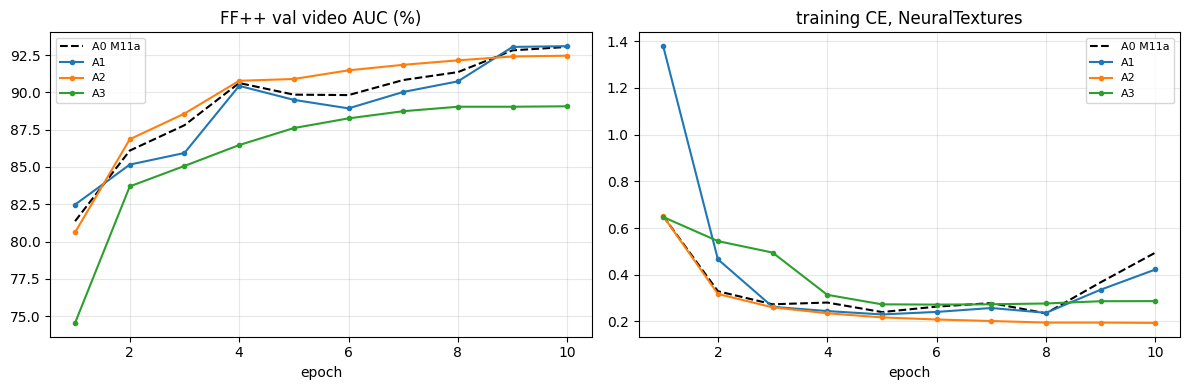

In [28]:
# 5.3 Curves
a0_hist = pd.DataFrame(json.loads((M11A_DIR / f"sbln_r{RANK}_{ARCH}_seed{SEED}" / "results.json").read_text())["history"])
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(a0_hist.epoch, a0_hist["val video AUC"], "k--", label="A0 M11a")
axes[1].plot(a0_hist.epoch, a0_hist["CE NT"], "k--", label="A0 M11a")
for rid, res in histories.items():
    h = pd.DataFrame(res["history"])
    axes[0].plot(h.epoch, h["val video AUC"], marker=".", label=rid)
    axes[1].plot(h.epoch, h["CE NT"], marker=".", label=rid)
axes[0].set_title("FF++ val video AUC (%)"); axes[1].set_title("training CE, NeuralTextures")
for ax in axes:
    ax.set_xlabel("epoch"); ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(M12_DIR / "curves.png", dpi=150); plt.show()